In [1]:
import os
import pandas as pd
import numpy as np

data_file = os.path.join(os.getcwd(), "..", "data", "transformed.csv")
dataframe = pd.read_csv(data_file, index_col="day")

In [2]:
print("NaN: ", dataframe.isna().sum().sum(), "in", dataframe.size, "cells")

NaN:  1677 in 88592 cells


In [3]:
print(dataframe.isna().sum().sort_values(ascending=False).head(10))

# top 10 ATMs with missing values

ATM_T95     29
ATM_T64     28
ATM_T16     26
ATM_T78     23
ATM_T51     23
ATM_T62     23
ATM_T101    23
ATM_T104    22
ATM_T88     22
ATM_T52     22
dtype: int64


In [4]:
def gap_lengths(s):
    
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    return isna.groupby(run_id).sum()[lambda x: x > 0]

gaps = pd.concat([gap_lengths(dataframe[c]) for c in dataframe if c.startswith("ATM")])
print(gaps.value_counts().sort_index())

# shows the gaps between NAN values, to see if gap is manageable like 1, 2 days or problematic like > 7 days.

1    810
2    366
3     25
4      5
5      4
6      1
7      2
Name: count, dtype: int64


Days where >50% of ATMs are NaN:  8
day
0    0.003319
1    0.002054
2    0.011694
3    0.002528
4    0.035319
5    0.070717
6    0.006874
dtype: float64


<Axes: title={'center': 'Share of ATMs missing per day'}, xlabel='day'>

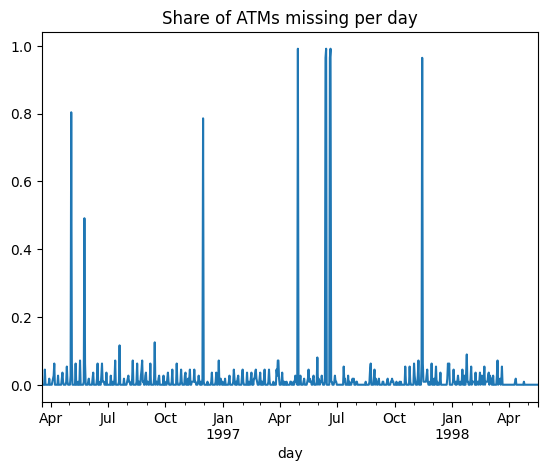

In [7]:
dataframe.index = pd.to_datetime(dataframe.index)

share = dataframe.isna().mean(axis=1)
print("Days where >50% of ATMs are NaN: ", (share > 0.5).sum())
print(dataframe.isna().groupby(dataframe.index.dayofweek).mean().mean(axis=1))
share.plot(title="Share of ATMs missing per day")

In [8]:
share = dataframe.isna().mean(axis=1)
sys_days = share[share > 0.5].index
print(pd.DataFrame({
    "share": share[sys_days].round(2),
    "weekday": sys_days.dayofweek
}))

print("NaN on systemic days: ", dataframe.loc[sys_days].isna().sum().sum(), "| isolated NaN: ", dataframe.drop(index=sys_days).isna().sum().sum())

isolated = dataframe.drop(index=sys_days)
print(isolated.isna().groupby(isolated.index.dayofweek).mean().mean(axis=1))
print(isolated.iloc[-56:].isna().sum().sum(), "NaN in the last 56 days")

                           share  weekday
day                                      
1996-05-04 00:00:00+00:00   0.80        5
1996-11-30 00:00:00+00:00   0.79        5
1997-04-30 00:00:00+00:00   0.99        2
1997-06-13 00:00:00+00:00   0.96        4
1997-06-14 00:00:00+00:00   0.99        5
1997-06-20 00:00:00+00:00   0.96        4
1997-06-21 00:00:00+00:00   0.99        5
1997-11-14 00:00:00+00:00   0.96        4
NaN on systemic days:  835 | isolated NaN:  842
day
0    0.003319
1    0.002054
2    0.002950
3    0.002528
4    0.009984
5    0.040547
6    0.006874
dtype: float64
4 NaN in the last 56 days


### ANALYSIS

A Total of 1600~ NaNs across the dataset. half of these values are on 8 days, when the NaN is across almost all ATMs. The other half is isolated, and scattered. In the last 56 days (which is the test window), there are just 4 missing values.

1) Split into train and test.
2) Fill each ATM using that weekday's data, so mondays for monday, tuesdays for tuesday, etc to maintain weekly signal.
3) We will compare weekday interpolation, weekday median, rolling weekday median. 

In [9]:
import numpy as np

HORIZON = 56
train, test = dataframe.iloc[:-HORIZON], dataframe.iloc[-HORIZON:]

def by_weekday(s, function):
    return s.groupby(s.index.dayofweek).transform(function)

METHODS = {
    "weekday_interpolation": lambda s: by_weekday(s, lambda x: x.interpolate(limit_direction="both")),
    "weekday_median": lambda s: s.fillna(by_weekday(s, "median")),
    "weekday_rollmed": lambda s: s.fillna(by_weekday(s, lambda x: x.rolling(5, center=True, min_periods=1).median())),
    "linear": lambda s: s.interpolate(limit_direction="both"),
}

def fill(s, name):
    return METHODS[name](s).fillna(s.median())

PATTERNS = [[0], [0, 1], [0, 1, 2, 3, 4], [0, 7], [0, 1, 7, 8]]
rng = np.random.default_rng(0); rows = []

for c in train:
    s = train[c]; scale = s.mean()
    for pat in PATTERNS:
        for _ in range(5):
            i = int(rng.integers(14, len(s) - 14 - max(pat))); idx = [i + k for k in pat]
            if s.iloc[i - 14:i + max(pat) + 14].isna().any(): continue  
            m = s.copy(); m.iloc[idx] = np.nan
            for name in METHODS:
                err = (fill(m, name).iloc[idx] - s.iloc[idx]).abs().mean() / scale
                rows.append((name, str(pat), err))
res = pd.DataFrame(rows, columns=["method", "pattern", "err"])
print(res.groupby("method").err.mean().sort_values().round(3))                      
print(res.pivot_table(index="method", columns="pattern", values="err").round(3)) 
    
BEST = res.groupby("method").err.mean().idxmin()
train_filled = train.apply(lambda s: fill(s, BEST))
assert train_filled.isna().sum().sum() == 0
print("used:", BEST, "| cells filled:", int(train.isna().sum().sum()))



method
weekday_rollmed          0.180
weekday_interpolation    0.198
weekday_median           0.199
linear                   0.310
Name: err, dtype: float64
pattern                [0, 1, 2, 3, 4]  [0, 1, 7, 8]  [0, 1]  [0, 7]    [0]
method                                                                     
linear                           0.417         0.327   0.299   0.261  0.253
weekday_interpolation            0.193         0.213   0.180   0.203  0.204
weekday_median                   0.195         0.209   0.190   0.189  0.210
weekday_rollmed                  0.175         0.198   0.165   0.181  0.183
used: weekday_rollmed | cells filled: 1673


In [10]:
train_filled.to_csv(os.path.join(os.getcwd(), "..", "data", "train_cleaned.csv"))
test.to_csv(os.path.join(os.getcwd(), "..", "data", "test.csv"))